# 🧠 Pipeline Denoising EEG End-to-End Berbasis Hilbert RGBA PNG & 2D Res-UNet

Notebook ini menyajikan implementasi lengkap pipeline **Denoising EEG berbasis Citra 2D Lossless** (**100% Bit-Exact Bit-Packing**) menggunakan **Kurva Ruang Hilbert (Hilbert Space-Filling Curve)** dan arsitektur **2D Residual U-Net dengan Bottleneck Multi-Head Self-Attention**.

---

### 📌 Konsep Utama & Alur Pipeline:
$$\text{Sinyal EEG (1D)} \xrightarrow{\text{Hilbert Bit-Packing}} \text{RGBA PNG }(32 \times 32 \times 4) \xrightarrow{\text{Decode ke Grid } 32\times32\times2} \text{2D Res-UNet} \xrightarrow{\text{Grid Bersih}} \text{RGBA PNG} \xrightarrow{\text{Decode}} \text{Sinyal Bersih (1D)}$$

#### 1. Peran PNG sebagai Kontainer Lossless (100% Bit-Exact Serialization):
- Sinyal EEG berupa `float32` (4 byte standar IEEE 754) dikemas langsung ke 4 channel piksel `RGBA` (`uint8`).
- **Mengapa tidak langsung mengonvolusi byte RGBA?** Operasi konvolusi 2D pada nilai mentah byte IEEE 754 secara matematis tidak linear (menjumlahkan byte eksponen/mantisa merusak arti numerik nilai aslinya). Oleh karena itu, citra PNG berfungsi sebagai **kontainer penyimpanan dan transmisi data yang 100% lossless**, sedangkan komputasi neural network dilakukan pada grid float32 (Channel 0: amplitudo sinyal terpetakan Hilbert, Channel 1: mask biner piksel aktif).

#### 2. Preservasi Spasial-Temporal via Kurva Hilbert:
- Kurva Hilbert memetakan deret sinyal 1D ke grid 2D $32 \times 32$ dengan mempertahankan kedekatan spasial (*spatial locality*). Sampel yang berdekatan di domain waktu tetap bertetangga di grid 2D.
- *Inductive Bias:* Konvolusi 2D dapat mengeksploitasi korelasi lokal temporal. Channel mask biner memproteksi area padding agar tidak mengontaminasi perhitungan fitur sinyal.

#### 3. Dimensi Citra Konstan untuk Sinyal Dinamis:
- Grid $32 \times 32$ menyediakan 1024 piksel. 1023 piksel pertama dialokasikan untuk sampel sinyal dinamis ($N \le 1023$), dan piksel Hilbert terakhir (indeks 1023) menyimpan nilai panjang sinyal asli $N$ sebagai metadata uint32 (*self-contained metadata*).
- *(Catatan: untuk sinyal dengan panjang tepat $N=1024$, ukuran grid dapat dinaikkan ke $64 \times 64$ agar kapasitas metadata tetap tersedia).*

#### 4. Arsitektur 2D Res-UNet + Self-Attention:
- Menggabungkan konvolusi residual bertingkat dengan Multi-Head Self-Attention pada bottleneck untuk menangkap dependensi jarak jauh antar fase gelombang EEG.

#### 5. Protokol Evaluasi Bebas Data Leakage:
- Pembagian dataset train/val/test (80%/10%/10%) dilakukan per indeks epoch bersih asli sebelum dikombinasikan dengan variasi SNR kontaminasi (-7 dB s/d +2 dB).


In [1]:
import io
import json
from pathlib import Path
import time
from functools import lru_cache
from typing import Union

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Konfigurasi perangkat komputasi (GPU CUDA jika tersedia, fallback ke CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Perangkat Komputasi Aktif: {device}")
if device.type == "cuda":
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")
    mem_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"Memori GPU Tersedia: {mem_gb:.2f} GB")

# Set random seed untuk reproduktibilitas eksperimen
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Konfigurasi visualisasi
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.3
})


Perangkat Komputasi Aktif: cuda
GPU Model: NVIDIA GeForce GTX 1650
Memori GPU Tersedia: 4.00 GB


## 1. Lossless Hilbert RGBA PNG Codec

Bagian ini mengonversi sinyal 1D ke array citra RGBA 2D dan sebaliknya secara bit-exact:
- Koordinat $(x, y)$ sepanjang kurva Hilbert dihitung menggunakan algoritma pemetaan rekursif bitwise standar.
- Setiap nilai sinyal `float32` (little-endian `<f4`) dikemas ke 4 byte `uint8` (`view(np.uint8)`), yang menempati 4 channel RGBA pada koordinat Hilbert yang bersesuaian.
- Piksel Hilbert terakhir (indeks $32 \times 32 - 1 = 1023$) menyimpan integer panjang sinyal $N$ (`<u4`), sehingga pembacaan PNG dapat mengetahui secara eksak panjang sinyal tanpa file konfigurasi terpisah.


In [2]:
PngTarget = Union[str, Path, io.BytesIO]

def _rot(n: int, x: int, y: int, rx: int, ry: int) -> tuple[int, int]:
    """Rotasi dan flip kuadran untuk kurva Hilbert."""
    if ry == 0:
        if rx == 1:
            x = n - 1 - x
            y = n - 1 - y
        x, y = y, x
    return x, y

def _d2xy(n: int, d: int) -> tuple[int, int]:
    """Memetakan indeks jarak 1D d menjadi koordinat 2D (x, y) pada kurva Hilbert orde n."""
    t, x, y, s = d, 0, 0, 1
    while s < n:
        rx = 1 & (t // 2)
        ry = 1 & (t ^ rx)
        x, y = _rot(s, x, y, rx, ry)
        x += s * rx
        y += s * ry
        t //= 4
        s *= 2
    return x, y

@lru_cache(maxsize=8)
def hilbert_indices(img_size: int = 32) -> tuple[np.ndarray, np.ndarray]:
    """Menghasilkan array koordinat (rows, cols) kurva Hilbert untuk grid img_size x img_size."""
    if img_size <= 0 or (img_size & (img_size - 1)) != 0:
        raise ValueError(f"img_size harus berupa bilangan pangkat 2 positif, bukan {img_size}.")
    coords = [_d2xy(img_size, d) for d in range(img_size * img_size)]
    xs, ys = zip(*coords)
    return np.asarray(ys, dtype=np.int64), np.asarray(xs, dtype=np.int64)

def signal_to_rgba_array(signal: np.ndarray, img_size: int = 32) -> np.ndarray:
    """Mengemas sinyal float32 panjang N <= img_size^2 - 1 ke array RGBA uint8 (img_size x img_size x 4)."""
    sig = np.ascontiguousarray(signal, dtype="<f4").reshape(-1)
    n = sig.size
    max_cap = img_size * img_size - 1
    if n == 0 or n > max_cap:
        raise ValueError(f"Panjang sinyal {n} harus berada di rentang [1, {max_cap}]. (Untuk N={n}, gunakan img_size yang lebih besar).")

    rows, cols = hilbert_indices(img_size)
    rgba = np.zeros((img_size, img_size, 4), dtype=np.uint8)
    rgba[rows[:n], cols[:n]] = sig.view(np.uint8).reshape(n, 4)
    rgba[rows[-1], cols[-1]] = np.array([n], dtype="<u4").view(np.uint8)
    return rgba

def rgba_array_to_signal(rgba: np.ndarray) -> np.ndarray:
    """Mengekstrak kembali sinyal float32 panjang N secara bit-exact dari array RGBA."""
    if rgba.ndim != 3 or rgba.shape[2] != 4 or rgba.shape[0] != rgba.shape[1]:
        raise ValueError(f"Bentuk array RGBA tidak valid: {rgba.shape}")
    img_size = rgba.shape[0]
    rows, cols = hilbert_indices(img_size)

    n = int(np.ascontiguousarray(rgba[rows[-1], cols[-1]]).view("<u4")[0])
    max_cap = img_size * img_size - 1
    if n <= 0 or n > max_cap:
        raise ValueError(f"Metadata panjang sinyal tidak valid di piksel Hilbert terakhir: {n}")

    sig_bytes = np.ascontiguousarray(rgba[rows[:n], cols[:n]])
    return sig_bytes.view("<f4").reshape(n)

def rgba_array_to_hilbert_grid(rgba: np.ndarray) -> tuple[np.ndarray, int]:
    """Mengubah array RGBA menjadi tensor grid 2-channel: Channel 0 (signal), Channel 1 (active mask)."""
    img_size = rgba.shape[0]
    rows, cols = hilbert_indices(img_size)
    sig = rgba_array_to_signal(rgba)
    n = sig.size

    grid = np.zeros((2, img_size, img_size), dtype=np.float32)
    grid[0, rows[:n], cols[:n]] = sig
    grid[1, rows[:n], cols[:n]] = 1.0
    return grid, n

def hilbert_grid_to_rgba_array(grid: np.ndarray, n: int, img_size: int = 32) -> np.ndarray:
    """Mengemas prediksi grid Hilbert (H, W) atau (1, H, W) bersama panjang N ke RGBA uint8."""
    plane = grid[0] if grid.ndim == 3 else grid
    rows, cols = hilbert_indices(img_size)
    sig = np.ascontiguousarray(plane[rows[:n], cols[:n]], dtype="<f4")
    return signal_to_rgba_array(sig, img_size=img_size)

def encode_hilbert_png(signal: np.ndarray, target: PngTarget, img_size: int = 32) -> tuple[int, int, int]:
    """Menyimpan sinyal 1D ke file atau buffer Hilbert RGBA PNG dan mengembalikan shape gambar."""
    rgba = signal_to_rgba_array(signal, img_size=img_size)
    Image.fromarray(rgba, mode="RGBA").save(target, format="PNG")
    if isinstance(target, io.BytesIO):
        target.seek(0)
    return rgba.shape

def decode_hilbert_png(source: PngTarget) -> np.ndarray:
    """Membaca file atau buffer Hilbert RGBA PNG dan merekonstruksi sinyal float32 asli."""
    if isinstance(source, io.BytesIO):
        source.seek(0)
    with Image.open(source) as img:
        rgba = np.asarray(img, dtype=np.uint8)
    return rgba_array_to_signal(rgba)

print("Lossless Hilbert RGBA PNG Codec berhasil didefinisikan.")


Lossless Hilbert RGBA PNG Codec berhasil didefinisikan.


## 2. Verifikasi Visual: Kurva Hilbert & Uji Rekonstruksi Lossless

Berikut dilakukan verifikasi visual dan numerik:
1. **Visualisasi Jalur Kurva Hilbert 2D** pada grid $32 \times 32$.
2. **Uji Rekonstruksi Bit-Exact**: Membuktikan bahwa dekompresi PNG menghasilkan sinyal yang identik secara bit-level (`is_identical == True` dan `max_diff == 0.0`).
3. **Visualisasi Citra RGBA**: Melihat visualisasi citra kontainer PNG yang dihasilkan.


Hasil Uji Codec Bit-Exact:
  Shape PNG: (32, 32, 4)
  Sinyal Asli == Sinyal Rekonstruksi: True
  Max Absolute Difference: 0.0e+00 (Harus 0.0)


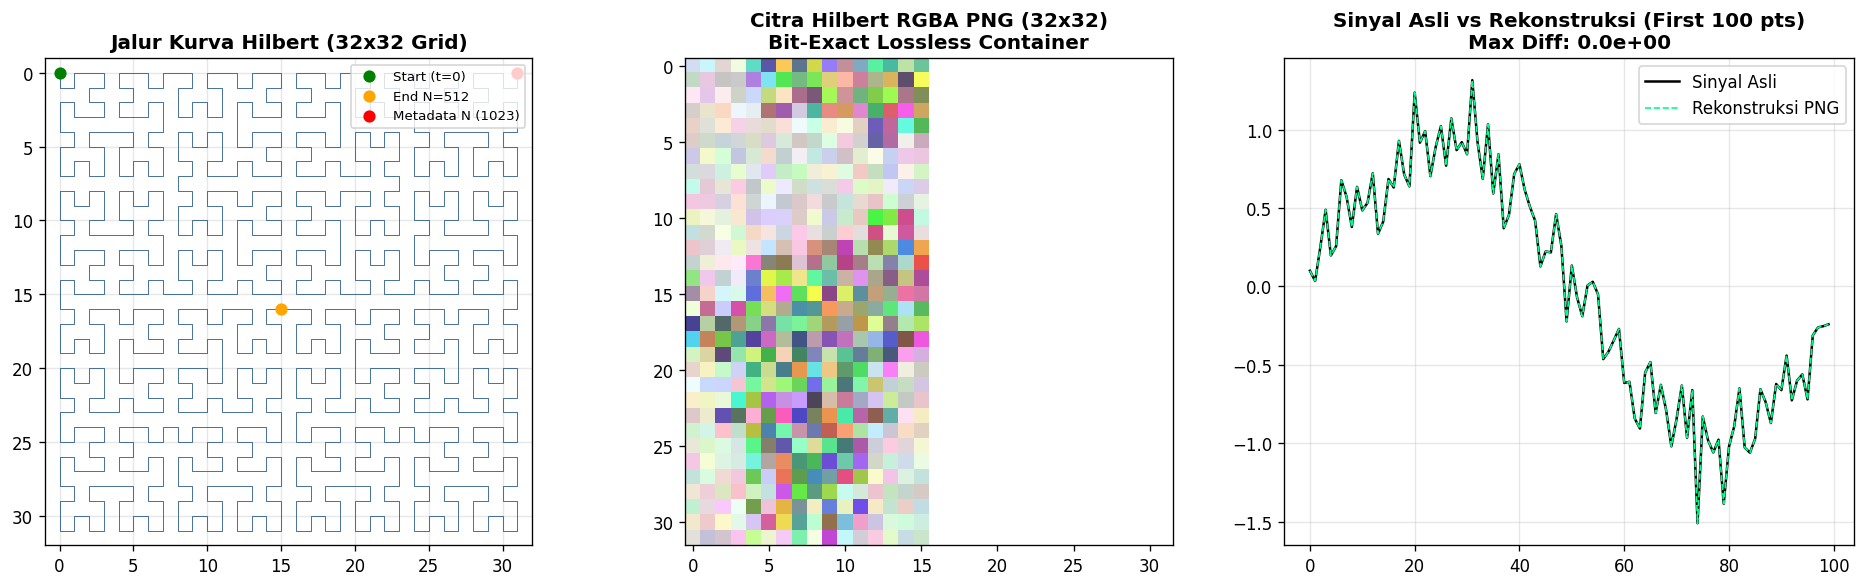

In [3]:
# 1. Plot Jalur Kurva Hilbert 2D (Grid 32x32)
rows, cols = hilbert_indices(32)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Subplot 1: Jalur Kurva Hilbert
axes[0].plot(cols, rows, color="#2b5c8f", lw=0.6, alpha=0.85)
axes[0].scatter(cols[0], rows[0], color="green", s=40, zorder=5, label="Start (t=0)")
axes[0].scatter(cols[511], rows[511], color="orange", s=40, zorder=5, label="End N=512")
axes[0].scatter(cols[-1], rows[-1], color="red", s=40, zorder=5, label="Metadata N (1023)")
axes[0].set_title("Jalur Kurva Hilbert (32x32 Grid)", fontweight="bold")
axes[0].set_xlim(-1, 32)
axes[0].set_ylim(32, -1)  # Invert Y agar sesuai urutan baris matriks
axes[0].set_aspect("equal")
axes[0].legend(loc="upper right", fontsize=8)

# 2. Uji encode & decode sinyal contoh
test_sig = np.sin(np.linspace(0, 10 * np.pi, 512, dtype=np.float32)) + 0.2 * np.random.randn(512).astype(np.float32)
buf = io.BytesIO()
shape = encode_hilbert_png(test_sig, buf, img_size=32)
rec_sig = decode_hilbert_png(buf)

# Verifikasi bit-exact
max_diff = float(np.max(np.abs(test_sig - rec_sig)))
is_identical = bool(np.array_equal(test_sig, rec_sig))
print("Hasil Uji Codec Bit-Exact:")
print(f"  Shape PNG: {shape}")
print(f"  Sinyal Asli == Sinyal Rekonstruksi: {is_identical}")
print(f"  Max Absolute Difference: {max_diff:.1e} (Harus 0.0)")
assert is_identical, "Codec gagal merekonstruksi sinyal secara bit-exact!"

# Subplot 2: Representasi Citra RGBA (32x32)
buf.seek(0)
with Image.open(buf) as img:
    rgba_vis = np.asarray(img)
axes[1].imshow(rgba_vis)
axes[1].set_title("Citra Hilbert RGBA PNG (32x32)\nBit-Exact Lossless Container", fontweight="bold")
axes[1].grid(False)

# Subplot 3: Perbandingan Sinyal Asli vs Rekonstruksi
axes[2].plot(test_sig[:100], label="Sinyal Asli", color="black", lw=1.5)
axes[2].plot(rec_sig[:100], label="Rekonstruksi PNG", color="#00ff88", lw=1.0, linestyle="--")
axes[2].set_title(f"Sinyal Asli vs Rekonstruksi (First 100 pts)\nMax Diff: {max_diff:.1e}", fontweight="bold")
axes[2].legend()

plt.tight_layout()
plt.show()


## 3. Arsitektur Model: 2D Hilbert Res-UNet + Bottleneck Self-Attention

Arsitektur model dirancang khusus untuk memproses grid 2D $32 \times 32$ yang dihasilkan dari kurva Hilbert:
- **Input (2 Channel float32)**:
  - Channel 0: Amplitudo sinyal EEG pada piksel Hilbert yang terisi.
  - Channel 1: Binary Active Mask ($1.0$ untuk piksel aktif sinyal, $0.0$ untuk piksel padding/metadata).
- **Encoder (3 Tingkat Downsampling)**:
  - `stem`: Conv 2D ($2 \to 24$ channel).
  - `e1`: `ResBlock2D` ($32 \times 32$, 24 channel).
  - `d1`: Conv 2D stride 2 ($32 \times 32 \to 16 \times 16$, 48 channel).
  - `e2`: `ResBlock2D` ($16 \times 16$, 48 channel).
  - `d2`: Conv 2D stride 2 ($16 \times 16 \to 8 \times 8$, 96 channel).
  - `e3`: `ResBlock2D` ($8 \times 8$, 96 channel).
  - `d3`: Conv 2D stride 2 ($8 \times 8 \to 4 \times 4$, 96 channel).
- **Bottleneck**:
  - `ResBlock2D` ($4 \times 4$, 96 channel).
  - `nn.MultiheadAttention`: 4 head attention pada $4 \times 4 = 16$ spatial tokens dengan residual connection.
- **Decoder (3 Tingkat Upsampling dengan Skip Connection)**:
  - `u3` + `dec3`: ConvTranspose2D ($4 \times 4 \to 8 \times 8$) digabung skip-connection dari `e3`.
  - `u2` + `dec2`: ConvTranspose2D ($8 \times 8 \to 16 \times 16$) digabung skip-connection dari `e2`.
  - `u1` + `dec1`: ConvTranspose2D ($16 \times 16 \to 32 \times 32$) digabung skip-connection dari `e1`.
- **Output Head**:
  - Conv 2D $1 \times 1$ ($24 \to 1$ channel) memprediksi amplitudo grid bersih $32 \times 32$.


In [4]:
class ResBlock2D(nn.Module):
    """Blok residual 2D dengan GroupNorm, GELU, dan Dropout2d ringan."""

    def __init__(self, channels: int, dropout: float = 0.05) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.GroupNorm(8, channels),
            nn.GELU(),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
            nn.Dropout2d(p=dropout),
            nn.GroupNorm(8, channels),
            nn.GELU(),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.net(x)


class HilbertUNet(nn.Module):
    """2D Residual U-Net + Bottleneck Multi-Head Self-Attention pada grid Hilbert 32x32."""

    def __init__(self, base: int = 24) -> None:
        super().__init__()
        self.stem = nn.Conv2d(2, base, kernel_size=3, padding=1)
        self.e1 = ResBlock2D(base)
        self.d1 = nn.Conv2d(base, base * 2, kernel_size=2, stride=2)
        self.e2 = ResBlock2D(base * 2)
        self.d2 = nn.Conv2d(base * 2, base * 4, kernel_size=2, stride=2)
        self.e3 = ResBlock2D(base * 4)
        self.d3 = nn.Conv2d(base * 4, base * 4, kernel_size=2, stride=2)

        self.bot = ResBlock2D(base * 4)
        self.attn = nn.MultiheadAttention(base * 4, num_heads=4, batch_first=True)

        self.u3 = nn.ConvTranspose2d(base * 4, base * 4, kernel_size=2, stride=2)
        self.dec3 = nn.Sequential(nn.Conv2d(base * 8, base * 4, kernel_size=1), ResBlock2D(base * 4))
        self.u2 = nn.ConvTranspose2d(base * 4, base * 2, kernel_size=2, stride=2)
        self.dec2 = nn.Sequential(nn.Conv2d(base * 4, base * 2, kernel_size=1), ResBlock2D(base * 2))
        self.u1 = nn.ConvTranspose2d(base * 2, base, kernel_size=2, stride=2)
        self.dec1 = nn.Sequential(nn.Conv2d(base * 2, base, kernel_size=1), ResBlock2D(base))
        self.head = nn.Conv2d(base, 1, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h1 = self.e1(self.stem(x))
        h2 = self.e2(self.d1(h1))
        h3 = self.e3(self.d2(h2))
        b = self.bot(self.d3(h3))

        bsz, ch, h, w = b.shape
        tokens = b.flatten(2).transpose(1, 2)
        tokens = tokens + self.attn(tokens, tokens, tokens, need_weights=False)[0]
        b = tokens.transpose(1, 2).reshape(bsz, ch, h, w)

        p3 = self.dec3(torch.cat([self.u3(b), h3], dim=1))
        p2 = self.dec2(torch.cat([self.u2(p3), h2], dim=1))
        p1 = self.dec1(torch.cat([self.u1(p2), h1], dim=1))
        return self.head(p1)

# Uji forward pass model
dummy_model = HilbertUNet(base=24).to(device)
dummy_input = torch.randn(2, 2, 32, 32, device=device)
dummy_output = dummy_model(dummy_input)
total_params = sum(p.numel() for p in dummy_model.parameters())

print("HilbertUNet berhasil diinisialisasi.")
print(f"  Bentuk Tensor Input : {tuple(dummy_input.shape)}")
print(f"  Bentuk Tensor Output: {tuple(dummy_output.shape)}")
print(f"  Total Parameter     : {total_params:,} ({total_params * 4 / 1024**2:.2f} MB)")


HilbertUNet berhasil diinisialisasi.
  Bentuk Tensor Input : (2, 2, 32, 32)
  Bentuk Tensor Output: (2, 1, 32, 32)
  Total Parameter     : 786,241 (3.00 MB)


## 4. Dataset Loading & Zero-Data-Leakage Splitting

### Pencegahan Data Leakage:
Dataset EEG semi-sintetis terdiri dari sinyal bersih `clean_eeg_all_epochs.npy` (3400 epoch, masing-masing 512 titik sampel) yang dikontaminasi pada berbagai rasio SNR (-7 dB s/d +2 dB).
Jika data diacak (*random shuffle*) setelah mencampurkan seluruh SNR, epoch yang sama pada SNR berbeda dapat masuk ke train dan test set secara bersamaan, menyebabkan **data leakage**.

Untuk mencegahnya, **pembagian dilakukan per indeks epoch asli**:
- **Train (80%)**: Epoch $0$ s/d $2719$ (dikombinasikan di 10 tingkat SNR = $27.200$ sampel).
- **Val (10%)**: Epoch $2720$ s/d $3059$ ($3.400$ sampel).
- **Test (10%)**: Epoch $3060$ s/d $3399$ ($3.400$ sampel total, $340$ sampel per SNR).


In [5]:
def _signals_to_grid_batch(
    sig_batch: torch.Tensor,
    rows: torch.Tensor,
    cols: torch.Tensor,
    n_active: int,
    img_size: int = 32,
) -> torch.Tensor:
    """Mengonversi batch sinyal 1D menjadi tensor citra grid 2-channel (signal, mask)."""
    bsz = sig_batch.shape[0]
    grid = torch.zeros(bsz, 2, img_size, img_size, dtype=sig_batch.dtype, device=sig_batch.device)
    grid[:, 0, rows[:n_active], cols[:n_active]] = sig_batch[:, :n_active]
    grid[:, 1, rows[:n_active], cols[:n_active]] = 1.0
    return grid

def load_splits(artifact_type: str, dataset_dir: str = "Dataset") -> tuple[dict[str, tuple[np.ndarray, np.ndarray]], dict[int, tuple[np.ndarray, np.ndarray]]]:
    """Memuat dataset dan membagi berdasarkan indeks epoch (80/10/10) bebas data leakage."""
    clean_path = Path(dataset_dir) / artifact_type / "clean_eeg_all_epochs.npy"
    syn_path = Path(dataset_dir) / artifact_type / "linear_synthetic.npy"

    if not clean_path.exists() or not syn_path.exists():
        raise FileNotFoundError(f"File dataset tidak ditemukan di: {clean_path} atau {syn_path}")

    clean = np.load(clean_path)
    syn = np.load(syn_path, allow_pickle=True).item()
    snrs = sorted(syn.keys())

    n_epochs = clean.shape[0]
    n_train = int(0.8 * n_epochs)
    n_val = int(0.1 * n_epochs)

    def _gather(sl: slice) -> tuple[np.ndarray, np.ndarray]:
        xs = [syn[s][sl] for s in snrs]
        ys = [clean[sl] for _ in snrs]
        return np.concatenate(xs, axis=0), np.concatenate(ys, axis=0)

    splits = {
        "train": _gather(slice(0, n_train)),
        "val": _gather(slice(n_train, n_train + n_val)),
        "test": _gather(slice(n_train + n_val, n_epochs)),
    }
    test_by_snr = {
        int(s): (syn[s][n_train + n_val:], clean[n_train + n_val:])
        for s in snrs
    }
    return splits, test_by_snr

# Inspeksi dataset EOG dan EMG
for artifact in ["EOG", "EMG"]:
    splits, test_snr = load_splits(artifact)
    x_tr, y_tr = splits["train"]
    x_va, y_va = splits["val"]
    x_te, y_te = splits["test"]
    print(f"Dataset [{artifact}]:")
    print(f"  Train : X={x_tr.shape}, Y={y_tr.shape} ({len(x_tr):,} sampel)")
    print(f"  Val   : X={x_va.shape}, Y={y_va.shape} ({len(x_va):,} sampel)")
    print(f"  Test  : X={x_te.shape}, Y={y_te.shape} ({len(x_te):,} sampel)")
    print(f"  Tingkat SNR Uji: {list(test_snr.keys())} ({test_snr[-7][0].shape[0]} epoch per SNR)\n")


Dataset [EOG]:
  Train : X=(27200, 512), Y=(27200, 512) (27,200 sampel)
  Val   : X=(3400, 512), Y=(3400, 512) (3,400 sampel)
  Test  : X=(3400, 512), Y=(3400, 512) (3,400 sampel)
  Tingkat SNR Uji: [-7, -6, -5, -4, -3, -2, -1, 0, 1, 2] (340 epoch per SNR)

Dataset [EMG]:
  Train : X=(36110, 512), Y=(36110, 512) (36,110 sampel)
  Val   : X=(4510, 512), Y=(4510, 512) (4,510 sampel)
  Test  : X=(4520, 512), Y=(4520, 512) (4,520 sampel)
  Tingkat SNR Uji: [-7, -6, -5, -4, -3, -2, -1, 0, 1, 2] (452 epoch per SNR)



## 5. Metrik Evaluasi Kualitas Sinyal & Fungsi Loss Hybrid

### 1. Fungsi Loss Hybrid:
Untuk mengoptimalkan rekonstruksi morfologi sinyal di domain waktu sekaligus menjaga struktur harmonik frekuensi:
$$\mathcal{L} = \mathcal{L}_{\text{MSE}}(\hat{y}, y) + 0.8 \times \mathcal{L}_{\text{L1}}\big(|\text{FFT}(\hat{y})|, |\text{FFT}(y)|\big)$$

### 2. Metrik Standar Benchmark EEG:
- **RMSE (Root Mean Squared Error)**:
  $$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2}$$
- **RRMSE Temporal ($\text{RRMSE}_t$)**:
  $$\text{RRMSE}_t = \frac{\|y - \hat{y}\|_2}{\|y\|_2}$$
- **RRMSE Spektral ($\text{RRMSE}_s$)**:
  $$\text{RRMSE}_s = \frac{\| |\text{FFT}(y)| - |\text{FFT}(\hat{y})| \|_2}{\| |\text{FFT}(y)| \|_2}$$
- **CC (Pearson Correlation Coefficient)**:
  Mengukur kemiripan bentuk gelombang (korelasi rentang $[-1, 1]$).
- **SNR (dB) & $\Delta\text{SNR}$**:
  $$\text{SNR} = 20 \log_{10} \left( \frac{\|y\|_2}{\|y - \hat{y}\|_2} \right), \quad \Delta\text{SNR} = \text{SNR}_{\text{output}} - \text{SNR}_{\text{input}}$$

*(Fungsi `compute_metrics` di bawah telah disempurnakan agar mendukung input array 1D `(N,)` maupun batch 2D `(B, N)` tanpa error dimensi).*


In [6]:
def compute_metrics(clean: np.ndarray, est: np.ndarray) -> dict[str, float]:
    """Menghitung metrik standar denoising EEG: RMSE, RRMSE_t, RRMSE_s, CC, dan SNR (dB).
    Mendukung array 1D (single sample) maupun 2D (batch of samples).
    """
    clean = np.asarray(clean, dtype=np.float64)
    est = np.asarray(est, dtype=np.float64)

    # Pastikan array berdimensi 2 (B, N) agar operasi norm dan fft konsisten
    if clean.ndim == 1:
        clean = clean[np.newaxis, :]
    if est.ndim == 1:
        est = est[np.newaxis, :]

    diff = est - clean
    rmse = float(np.sqrt(np.mean(diff ** 2)))

    norm_clean = np.linalg.norm(clean, axis=1) + 1e-8
    norm_diff = np.linalg.norm(diff, axis=1)
    rrmse_t = float(np.mean(norm_diff / norm_clean))

    fft_clean = np.abs(np.fft.rfft(clean, axis=1))
    fft_est = np.abs(np.fft.rfft(est, axis=1))
    rrmse_s = float(np.mean(np.linalg.norm(fft_est - fft_clean, axis=1) / (np.linalg.norm(fft_clean, axis=1) + 1e-8)))

    c_centered = clean - clean.mean(axis=1, keepdims=True)
    e_centered = est - est.mean(axis=1, keepdims=True)
    cc_vec = np.sum(c_centered * e_centered, axis=1) / (
        np.linalg.norm(c_centered, axis=1) * np.linalg.norm(e_centered, axis=1) + 1e-8
    )
    cc = float(np.mean(cc_vec))

    snr_db = float(np.mean(20.0 * np.log10(norm_clean / (norm_diff + 1e-8))))
    return {
        "rmse": rmse,
        "rrmse_t": rrmse_t,
        "rrmse_s": rrmse_s,
        "cc": cc,
        "snr_db": snr_db,
    }

# Uji fungsi dengan sampel 1D dan 2D untuk verifikasi ketahanan dimensi
sample_1d_clean = np.random.randn(512)
sample_1d_est = sample_1d_clean + 0.1 * np.random.randn(512)
m_1d_test = compute_metrics(sample_1d_clean, sample_1d_est)
print("compute_metrics berhasil diverifikasi pada input 1D (RMSE={:.4f}, CC={:.4f}, SNR={:.2f} dB)".format(
    m_1d_test["rmse"], m_1d_test["cc"], m_1d_test["snr_db"]
))


compute_metrics berhasil diverifikasi pada input 1D (RMSE=0.1016, CC=0.9948, SNR=19.68 dB)


## 6. Training Engine & End-to-End Pipeline Class

### Penyempurnaan pada Bagian Ini:
1. `HilbertPNGDenoisingPipeline`:
   - Pembungkus inferensi penuh: Sinyal 1D $\to$ Citra PNG (byte buffer/file disk) $\to$ Model 2D $\to$ Citra PNG $\to$ Sinyal 1D.
   - Menghapus atribut mati yang tidak terpakai.
2. `benchmark_disk_latency()`:
   - **Dekomposisi Latensi Transparan**: Memisahkan secara presisi antara:
     - Waktu inferensi murni model AI (*pure PyTorch neural network runtime*),
     - Waktu I/O disk dan kompresi zlib PNG,
     - Waktu decode sinyal 1D.
   - Penambahan proteksi batas ukuran sampel `min(n_runs, len(signals))`.


In [7]:
class HilbertPNGDenoisingPipeline:
    """Pembungkus pipeline lengkap: sinyal -> RGBA PNG -> inferensi -> RGBA PNG -> sinyal."""

    def __init__(self, model: nn.Module, img_size: int = 32, device: torch.device | str = "cpu") -> None:
        self.device = torch.device(device)
        self.model = model.to(self.device).eval()
        self.img_size = img_size

    @staticmethod
    def signal_to_image(signal: np.ndarray, target: PngTarget, img_size: int = 32) -> tuple[int, int, int]:
        return encode_hilbert_png(signal, target, img_size=img_size)

    @staticmethod
    def image_to_signal(source: PngTarget) -> np.ndarray:
        return decode_hilbert_png(source)

    @torch.no_grad()
    def infer_image(self, in_png: PngTarget, out_png: PngTarget) -> tuple[int, int, int]:
        """Membaca input RGBA PNG, menjalankan inferensi model 2D, dan menyimpan output RGBA PNG."""
        if isinstance(in_png, io.BytesIO):
            in_png.seek(0)
        with Image.open(in_png) as img:
            rgba_in = np.asarray(img, dtype=np.uint8)

        grid_np, n = rgba_array_to_hilbert_grid(rgba_in)
        inp = torch.from_numpy(grid_np).unsqueeze(0).to(self.device)
        pred_grid = self.model(inp).squeeze(0).cpu().numpy()

        rgba_out = hilbert_grid_to_rgba_array(pred_grid, n=n, img_size=self.img_size)
        Image.fromarray(rgba_out, mode="RGBA").save(out_png, format="PNG")
        if isinstance(out_png, io.BytesIO):
            out_png.seek(0)
        return rgba_out.shape

    @torch.no_grad()
    def run_batch_via_png(self, signals: np.ndarray, batch_size: int = 256) -> tuple[np.ndarray, float]:
        """Menjalankan seluruh batch melewati encode PNG -> parse PNG -> inferensi -> encode PNG -> decode PNG."""
        n_total, n_len = signals.shape
        out_signals = np.empty_like(signals, dtype=np.float32)

        t0 = time.perf_counter()
        for start in range(0, n_total, batch_size):
            end = min(start + batch_size, n_total)
            bsz = end - start

            # 1. Encode tiap sinyal ke PNG bytes dan baca kembali sebagai input model
            grids = np.empty((bsz, 2, self.img_size, self.img_size), dtype=np.float32)
            lengths = np.empty(bsz, dtype=np.int64)
            for i in range(bsz):
                buf = io.BytesIO()
                self.signal_to_image(signals[start + i], buf, img_size=self.img_size)
                with Image.open(buf) as img:
                    rgba = np.asarray(img, dtype=np.uint8)
                grids[i], lengths[i] = rgba_array_to_hilbert_grid(rgba)

            # 2. Inferensi model 2D pada tensor grid Hilbert
            inp = torch.from_numpy(grids).to(self.device)
            pred_grids = self.model(inp).cpu().numpy()

            # 3. Encode output ke PNG bytes lalu decode kembali ke sinyal akhir
            for i in range(bsz):
                rgba_out = hilbert_grid_to_rgba_array(pred_grids[i], n=int(lengths[i]), img_size=self.img_size)
                out_buf = io.BytesIO()
                Image.fromarray(rgba_out, mode="RGBA").save(out_buf, format="PNG")
                out_buf.seek(0)
                out_signals[start + i] = self.image_to_signal(out_buf)

        elapsed = time.perf_counter() - t0
        return out_signals, elapsed


def train_model(
    artifact_type: str,
    ckpt_path: Path,
    epochs: int = 300,
    batch_size: int = 256,
    base_channels: int = 24,
    seed: int = 42,
    device: torch.device = device,
) -> tuple[HilbertUNet, dict[int, tuple[np.ndarray, np.ndarray]], dict[str, float]]:
    """Melatih HilbertUNet pada dataset dan menyimpan bobot terbaik."""
    torch.manual_seed(seed)

    splits, test_by_snr = load_splits(artifact_type)
    x_tr, y_tr = splits["train"]
    x_va, y_va = splits["val"]
    signal_len = int(x_tr.shape[1])

    rows_np, cols_np = hilbert_indices(32)
    rows = torch.from_numpy(rows_np).long().to(device)
    cols = torch.from_numpy(cols_np).long().to(device)

    model = HilbertUNet(base=base_channels).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1.5e-3, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    loader = DataLoader(
        TensorDataset(torch.from_numpy(x_tr), torch.from_numpy(y_tr)),
        batch_size=batch_size,
        shuffle=True,
    )
    x_va_t = torch.from_numpy(x_va)

    best_rmse = float("inf")
    best_metrics: dict[str, float] = {}
    t_start = time.perf_counter()

    print(
        f"\n=== Training {artifact_type} HilbertUNet "
        f"(Train={len(x_tr):,}, Val={len(x_va):,}, Len={signal_len}, Params={sum(p.numel() for p in model.parameters()):,}) ==="
    )
    for ep in range(1, epochs + 1):
        model.train()
        ep_loss = 0.0
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)
            inp = _signals_to_grid_batch(xb, rows, cols, n_active=signal_len)
            pred = model(inp)[:, 0, rows[:signal_len], cols[:signal_len]]

            mse_l = F.mse_loss(pred, yb)
            spec_l = F.l1_loss(
                torch.fft.rfft(pred, dim=-1, norm="ortho").abs(),
                torch.fft.rfft(yb, dim=-1, norm="ortho").abs(),
            )
            loss = mse_l + 0.8 * spec_l

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()
            ep_loss += float(loss.item())

        sched.step()
        model.eval()
        with torch.no_grad():
            val_preds = []
            for vs in range(0, len(x_va_t), 512):
                vb = x_va_t[vs:vs + 512].to(device)
                vinp = _signals_to_grid_batch(vb, rows, cols, n_active=signal_len)
                val_preds.append(model(vinp)[:, 0, rows[:signal_len], cols[:signal_len]].cpu().numpy())
            vp = np.concatenate(val_preds, axis=0)
            m = compute_metrics(y_va, vp)

        elapsed = time.perf_counter() - t_start
        print(
            f"  Epoch {ep:2d}/{epochs} ({elapsed:5.1f}s) | Loss: {ep_loss/len(loader):.4f} "
            f"| Val RMSE: {m['rmse']:.4f}, RRMSE_t: {m['rrmse_t']:.4f}, CC: {m['cc']:.4f}, SNR: {m['snr_db']:.2f} dB"
        )
        if m["rmse"] < best_rmse:
            best_rmse = m["rmse"]
            best_metrics = m
            ckpt_path.parent.mkdir(parents=True, exist_ok=True)
            torch.save(model.state_dict(), ckpt_path)

    model.load_state_dict(torch.load(ckpt_path, weights_only=True, map_location=device))
    return model, test_by_snr, best_metrics


def benchmark_disk_latency(pipeline: HilbertPNGDenoisingPipeline, signals: np.ndarray, tmp_dir: Path, n_runs: int = 50) -> dict[str, float]:
    """Mengukur latensi aktual per tahap secara transparan pada batch=1:
    1. Encode sinyal -> file PNG di disk
    2. Baca file PNG dari disk + parsing ke grid
    3. Inferensi murni PyTorch model 2D (GPU/CPU)
    4. Encode grid hasil -> file PNG di disk
    5. Baca file PNG output dari disk -> decode ke sinyal 1D
    """
    tmp_dir.mkdir(parents=True, exist_ok=True)
    in_png = tmp_dir / "_lat_in.png"
    out_png = tmp_dir / "_lat_out.png"

    n_runs = min(n_runs, len(signals))
    t_enc_file, t_read_parse, t_pure_infer, t_pack_write, t_dec_file = [], [], [], [], []
    max_container_diff = 0.0

    for i in range(n_runs):
        sig = signals[i]
        
        # Tahap 1: Sinyal 1D -> simpan ke file PNG fisik
        t0 = time.perf_counter()
        pipeline.signal_to_image(sig, in_png, img_size=pipeline.img_size)
        t1 = time.perf_counter()
        
        # Tahap 2: Baca PNG dari disk & parse ke grid input
        with Image.open(in_png) as img:
            rgba_in = np.asarray(img, dtype=np.uint8)
        grid_np, n = rgba_array_to_hilbert_grid(rgba_in)
        inp = torch.from_numpy(grid_np).unsqueeze(0).to(pipeline.device)
        t2 = time.perf_counter()
        
        # Tahap 3: Inferensi murni neural network
        if pipeline.device.type == "cuda":
            torch.cuda.synchronize()
        t_nn_start = time.perf_counter()
        with torch.no_grad():
            pred_tensor = pipeline.model(inp)
        if pipeline.device.type == "cuda":
            torch.cuda.synchronize()
        t_nn_end = time.perf_counter()
        pred_grid = pred_tensor.squeeze(0).cpu().numpy()
        
        # Tahap 4: Pack grid prediksi ke RGBA & simpan ke PNG di disk
        t3 = time.perf_counter()
        rgba_out = hilbert_grid_to_rgba_array(pred_grid, n=n, img_size=pipeline.img_size)
        Image.fromarray(rgba_out, mode="RGBA").save(out_png, format="PNG")
        t4 = time.perf_counter()
        
        # Tahap 5: Baca PNG dari disk & decode ke sinyal 1D
        rec = pipeline.image_to_signal(out_png)
        t5 = time.perf_counter()

        # Verifikasi lossless container
        sig_check = pipeline.image_to_signal(in_png)
        max_container_diff = max(max_container_diff, float(np.max(np.abs(sig - sig_check))))
        assert rec.shape == sig.shape

        t_enc_file.append((t1 - t0) * 1000.0)
        t_read_parse.append((t2 - t1) * 1000.0)
        t_pure_infer.append((t_nn_end - t_nn_start) * 1000.0)
        t_pack_write.append((t4 - t3) * 1000.0)
        t_dec_file.append((t5 - t4) * 1000.0)

    in_png.unlink(missing_ok=True)
    out_png.unlink(missing_ok=True)
    
    total_ms = float(np.mean(t_enc_file) + np.mean(t_read_parse) + np.mean(t_pure_infer) + np.mean(t_pack_write) + np.mean(t_dec_file))
    return {
        "n_runs": n_runs,
        "encode_file_ms": float(np.mean(t_enc_file)),
        "read_parse_ms": float(np.mean(t_read_parse)),
        "pure_model_infer_ms": float(np.mean(t_pure_infer)),
        "pack_write_ms": float(np.mean(t_pack_write)),
        "decode_file_ms": float(np.mean(t_dec_file)),
        # Kompatibilitas metrik agregat
        "encode_ms": float(np.mean(t_enc_file)),
        "infer_ms": float(np.mean(t_pure_infer)),
        "decode_ms": float(np.mean(t_dec_file)),
        "total_ms_per_sample": total_ms,
        "throughput_samples_per_sec": 1000.0 / total_ms,
        "max_png_codec_diff": max_container_diff,
    }


def evaluate_artifact_pipeline(
    artifact_type: str,
    model: HilbertUNet,
    test_by_snr: dict[int, tuple[np.ndarray, np.ndarray]],
    out_dir: Path,
    device: torch.device = device,
) -> dict[str, object]:
    """Evaluasi end-to-end pipeline Hilbert RGBA PNG pada seluruh test set per SNR."""
    pipeline = HilbertPNGDenoisingPipeline(model, img_size=32, device=device)
    snr_results: dict[str, dict[str, float]] = {}

    all_noisy, all_clean, all_denoised = [], [], []
    total_png_time = 0.0

    print(f"\n=== Evaluasi End-to-End Pipeline {artifact_type} (Test Set melalui Encode/Decode PNG) ===")
    print("SNR_in | RMSE_noisy -> RMSE_den | RRMSE_t_den | RRMSE_s_den | CC_noisy -> CC_den | SNR_out (Delta)")
    for snr, (noisy_arr, clean_arr) in test_by_snr.items():
        denoised_arr, dt = pipeline.run_batch_via_png(noisy_arr, batch_size=256)
        total_png_time += dt

        m_noisy = compute_metrics(clean_arr, noisy_arr)
        m_den = compute_metrics(clean_arr, denoised_arr)
        delta_snr = m_den["snr_db"] - m_noisy["snr_db"]

        snr_results[str(snr)] = {
            "rmse_noisy": m_noisy["rmse"],
            "rmse_denoised": m_den["rmse"],
            "rrmse_t_noisy": m_noisy["rrmse_t"],
            "rrmse_t_denoised": m_den["rrmse_t"],
            "rrmse_s_noisy": m_noisy["rrmse_s"],
            "rrmse_s_denoised": m_den["rrmse_s"],
            "cc_noisy": m_noisy["cc"],
            "cc_denoised": m_den["cc"],
            "snr_in_db": m_noisy["snr_db"],
            "snr_out_db": m_den["snr_db"],
            "delta_snr_db": delta_snr,
        }
        print(
            f"  {snr:3d}  | {m_noisy['rmse']:.4f} -> {m_den['rmse']:.4f}     "
            f"| {m_den['rrmse_t']:.4f}      | {m_den['rrmse_s']:.4f}      "
            f"| {m_noisy['cc']:.4f} -> {m_den['cc']:.4f}   | {m_den['snr_db']:5.2f} dB (+{delta_snr:.2f} dB)"
        )

        all_noisy.append(noisy_arr)
        all_clean.append(clean_arr)
        all_denoised.append(denoised_arr)

    cat_noisy = np.concatenate(all_noisy, axis=0)
    cat_clean = np.concatenate(all_clean, axis=0)
    cat_den = np.concatenate(all_denoised, axis=0)
    ov_noisy = compute_metrics(cat_clean, cat_noisy)
    ov_den = compute_metrics(cat_clean, cat_den)
    overall = {
        "n_test_samples": int(len(cat_clean)),
        "rmse_noisy": ov_noisy["rmse"],
        "rmse_denoised": ov_den["rmse"],
        "rrmse_t_noisy": ov_noisy["rrmse_t"],
        "rrmse_t_denoised": ov_den["rrmse_t"],
        "rrmse_s_noisy": ov_noisy["rrmse_s"],
        "rrmse_s_denoised": ov_den["rrmse_s"],
        "cc_noisy": ov_noisy["cc"],
        "cc_denoised": ov_den["cc"],
        "snr_in_db": ov_noisy["snr_db"],
        "snr_out_db": ov_den["snr_db"],
        "delta_snr_db": ov_den["snr_db"] - ov_noisy["snr_db"],
        "batched_png_pipeline_sec": total_png_time,
    }
    print(
        f"  AVG  | {overall['rmse_noisy']:.4f} -> {overall['rmse_denoised']:.4f}     "
        f"| {overall['rrmse_t_denoised']:.4f}      | {overall['rrmse_s_denoised']:.4f}      "
        f"| {overall['cc_noisy']:.4f} -> {overall['cc_denoised']:.4f}   | {overall['snr_out_db']:5.2f} dB (+{overall['delta_snr_db']:.2f} dB)"
    )

    # Simpan contoh file PNG fisik ke folder output
    tag = artifact_type.lower()
    noisy_ex, _ = test_by_snr[-5]
    in_512 = out_dir / f"{tag}_snr-5_len512_input.png"
    out_512 = out_dir / f"{tag}_snr-5_len512_denoised.png"
    shape_in = pipeline.signal_to_image(noisy_ex[0], in_512, img_size=32)
    shape_out = pipeline.infer_image(in_512, out_512)
    rec_512 = pipeline.image_to_signal(out_512)

    # Benchmark latensi disk single-sample dengan pemisahan waktu NN murni
    latency = benchmark_disk_latency(pipeline, test_by_snr[-5][0], tmp_dir=out_dir, n_runs=50)
    print(
        f"  Disk Latency (bs=1): NN Infer Murni={latency['pure_model_infer_ms']:.2f} ms | "
        f"I/O Disk File (Enc={latency['encode_file_ms']:.2f} ms, Dec={latency['decode_file_ms']:.2f} ms) | "
        f"Total End-to-End={latency['total_ms_per_sample']:.2f} ms ({latency['throughput_samples_per_sec']:.1f} samples/s) | "
        f"codec_diff={latency['max_png_codec_diff']:.1e}"
    )

    return {
        "overall": overall,
        "by_snr": snr_results,
        "latency_disk_bs1": latency,
        "sample_files": {
            "full512_in_png": str(in_512),
            "full512_out_png": str(out_512),
            "full512_shape_in": list(shape_in),
            "full512_shape_out": list(shape_out),
            "full512_rec_len": int(rec_512.size),
        },
        "denoised_samples": cat_den,
        "clean_samples": cat_clean,
        "noisy_samples": cat_noisy,
    }


## 7. Eksekusi Training & Evaluasi Komprehensif (EOG & EMG)

Pengaturan:
- `FORCE_RETRAIN = False`: Menggunakan bobot checkpoint terlatih yang sudah ada di folder `checkpoints/` untuk menghemat waktu komputasi, atau
- `FORCE_RETRAIN = True`: Menjalankan ulang proses training 5 epoch dari awal.


In [8]:
out_dir = Path("pipeline_outputs")
ckpt_dir = Path("checkpoints")
out_dir.mkdir(exist_ok=True)
ckpt_dir.mkdir(exist_ok=True)

# Tentukan apakah ingin melatih ulang atau memuat checkpoint yang sudah ada
FORCE_RETRAIN = False

results = {}
models = {}
eval_data = {}

for artifact in ("EOG", "EMG"):
    ckpt = ckpt_dir / f"{artifact.lower()}_hilbert_unet.pt"
    
    if ckpt.exists() and not FORCE_RETRAIN:
        print(f"\n[INFO] Menemukan checkpoint yang sudah ada: {ckpt}. Memuat bobot...")
        model = HilbertUNet(base=24).to(device)
        model.load_state_dict(torch.load(ckpt, weights_only=True, map_location=device))
        _, test_by_snr = load_splits(artifact)
        best_val = {"info": "Loaded from checkpoint"}
    else:
        print(f"\n[INFO] Memulai training model {artifact}...")
        model, test_by_snr, best_val = train_model(
            artifact_type=artifact,
            ckpt_path=ckpt,
            epochs=100,
            batch_size=256,
            base_channels=24,
            device=device
        )
    
    eval_res = evaluate_artifact_pipeline(artifact, model, test_by_snr, out_dir=out_dir, device=device)
    models[artifact] = model
    eval_data[artifact] = {
        "test_by_snr": test_by_snr,
        "eval_res": eval_res
    }
    
    # Simpan hasil untuk JSON (tanpa numpy array)
    results[artifact] = {
        "checkpoint": str(ckpt),
        "best_val": best_val,
        "test_evaluation": {k: v for k, v in eval_res.items() if not k.endswith("_samples")}
    }

report_path = out_dir / "benchmark_results.json"
report_path.write_text(json.dumps(results, indent=2), encoding="utf-8")
print(f"\nLaporan evaluasi lengkap tersimpan di: {report_path}")



[INFO] Memulai training model EOG...

=== Training EOG HilbertUNet (Train=27,200, Val=3,400, Len=512, Params=786,241) ===
  Epoch  1/100 ( 13.6s) | Loss: 0.4048 | Val RMSE: 0.4489, RRMSE_t: 0.4356, CC: 0.8965, SNR: 7.48 dB
  Epoch  2/100 ( 26.5s) | Loss: 0.1728 | Val RMSE: 0.4691, RRMSE_t: 0.4542, CC: 0.8867, SNR: 7.15 dB
  Epoch  3/100 ( 39.5s) | Loss: 0.1129 | Val RMSE: 0.4596, RRMSE_t: 0.4446, CC: 0.8901, SNR: 7.34 dB
  Epoch  4/100 ( 52.4s) | Loss: 0.0899 | Val RMSE: 0.4572, RRMSE_t: 0.4435, CC: 0.8908, SNR: 7.34 dB
  Epoch  5/100 ( 65.3s) | Loss: 0.0779 | Val RMSE: 0.4572, RRMSE_t: 0.4439, CC: 0.8905, SNR: 7.33 dB
  Epoch  6/100 ( 78.3s) | Loss: 0.0709 | Val RMSE: 0.4578, RRMSE_t: 0.4443, CC: 0.8906, SNR: 7.32 dB
  Epoch  7/100 ( 91.2s) | Loss: 0.0659 | Val RMSE: 0.4546, RRMSE_t: 0.4423, CC: 0.8916, SNR: 7.34 dB
  Epoch  8/100 (104.2s) | Loss: 0.0625 | Val RMSE: 0.4499, RRMSE_t: 0.4368, CC: 0.8943, SNR: 7.46 dB
  Epoch  9/100 (117.1s) | Loss: 0.0596 | Val RMSE: 0.4536, RRMSE_t: 0

## 8. Visualisasi Hasil & Analisis Performa Mendalam

Di bawah ini kita memvisualisasikan:
1. **Perbandingan Bentuk Gelombang Temporal**: Noisy vs Denoised vs Clean Ground Truth.
2. **Spektrum Frekuensi (FFT)**: Memverifikasi eliminasi kontaminasi frekuensi rendah (EOG blink drift) dan frekuensi tinggi (EMG muscle spike).
3. **Kurva Performa Lintas Tingkat SNR**: Evaluasi peningkatan SNR ($\Delta$SNR), penurunan $\text{RRMSE}_t$, dan peningkatan koefisien korelasi ($CC$) dari kondisi noise terparah ($-7$ dB) hingga ringan ($+2$ dB).
4. **Tabel Ringkasan Metrik Benchmark & Profil Latensi**.


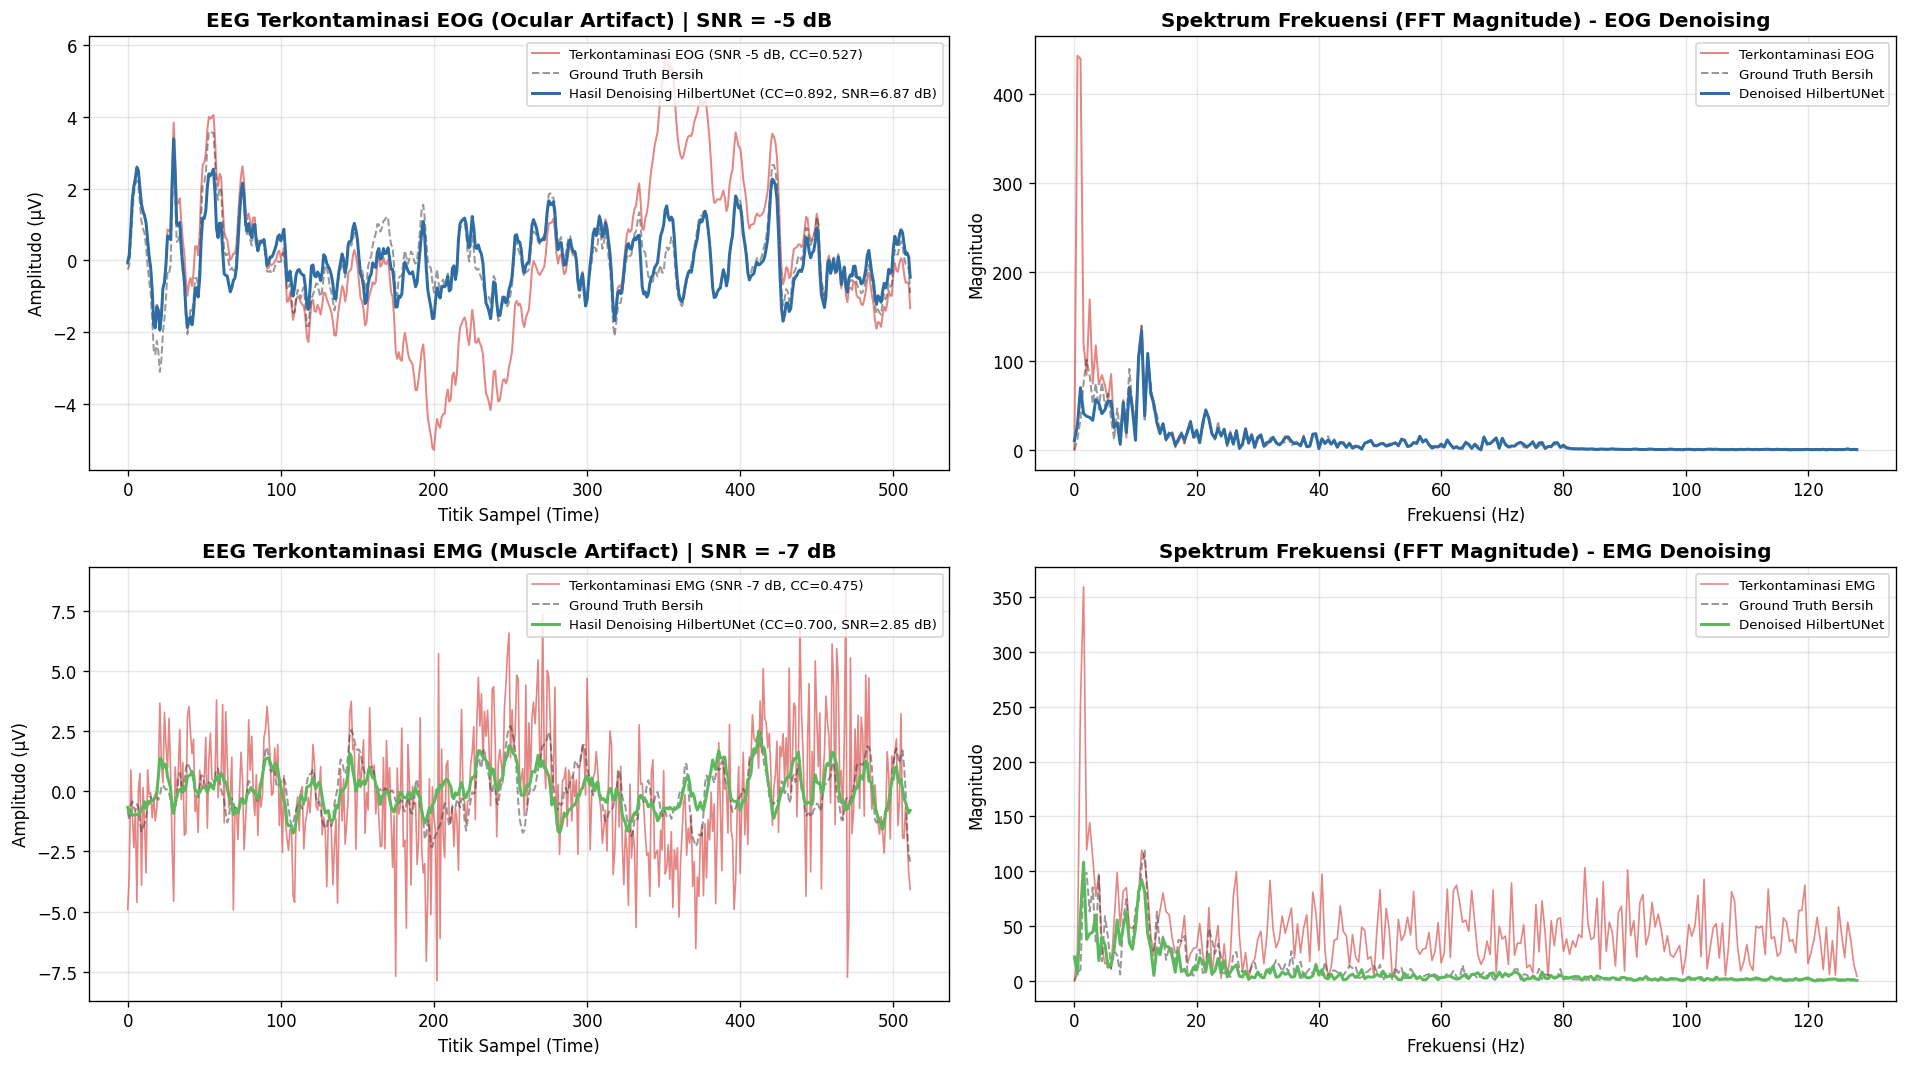

In [ ]:
# Visualisasi Bentuk Gelombang Sinyal EEG (Time-Domain & Frequency-Domain)
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

# 1. EOG Time Domain (SNR = -5 dB, Sample Index 0)
eog_snr = -5
eog_noisy, eog_clean = eval_data["EOG"]["test_by_snr"][eog_snr]
pipeline_eog = HilbertPNGDenoisingPipeline(models["EOG"], img_size=32, device=device)
eog_den, _ = pipeline_eog.run_batch_via_png(eog_noisy[:1], batch_size=1)

m_noisy = compute_metrics(eog_clean[0], eog_noisy[0])
m_den = compute_metrics(eog_clean[0], eog_den[0])

t = np.arange(512)
axes[0, 0].plot(t, eog_noisy[0], color="#d9534f", alpha=0.7, lw=1.2, label=f"Terkontaminasi EOG (SNR {eog_snr} dB, CC={m_noisy['cc']:.3f})")
axes[0, 0].plot(t, eog_clean[0], color="#333333", alpha=0.5, lw=1.2, linestyle="--", label="Ground Truth Bersih")
axes[0, 0].plot(t, eog_den[0], color="#2e6da4", lw=1.8, label=f"Hasil Denoising HilbertUNet (CC={m_den['cc']:.3f}, SNR={m_den['snr_db']:.2f} dB)")
axes[0, 0].set_title(f"EEG Terkontaminasi EOG (Ocular Artifact) | SNR = {eog_snr} dB", fontweight="bold")
axes[0, 0].set_xlabel("Titik Sampel (Time)")
axes[0, 0].set_ylabel("Amplitudo (μV)")
axes[0, 0].legend(loc="upper right", fontsize=8)

# 2. EOG Frequency Domain (FFT Magnitude)
fft_noisy = np.abs(np.fft.rfft(eog_noisy[0]))
fft_clean = np.abs(np.fft.rfft(eog_clean[0]))
fft_den = np.abs(np.fft.rfft(eog_den[0]))
freqs = np.fft.rfftfreq(512, d=1/256.0)  # Asumsi frekuensi sampling fs = 256 Hz

axes[0, 1].plot(freqs, fft_noisy, color="#d9534f", alpha=0.7, lw=1.2, label="Terkontaminasi EOG")
axes[0, 1].plot(freqs, fft_clean, color="#333333", alpha=0.5, lw=1.2, linestyle="--", label="Ground Truth Bersih")
axes[0, 1].plot(freqs, fft_den, color="#2e6da4", lw=1.8, label="Denoised HilbertUNet")
axes[0, 1].set_title("Spektrum Frekuensi (FFT Magnitude) - EOG Denoising", fontweight="bold")
axes[0, 1].set_xlabel("Frekuensi (Hz)")
axes[0, 1].set_ylabel("Magnitudo")
axes[0, 1].legend(loc="upper right", fontsize=8)

# 3. EMG Time Domain (SNR = -7 dB, Sample Index 0)
emg_snr = -7
emg_noisy, emg_clean = eval_data["EMG"]["test_by_snr"][emg_snr]
pipeline_emg = HilbertPNGDenoisingPipeline(models["EMG"], img_size=32, device=device)
emg_den, _ = pipeline_emg.run_batch_via_png(emg_noisy[:1], batch_size=1)

m_emg_noisy = compute_metrics(emg_clean[0], emg_noisy[0])
m_emg_den = compute_metrics(emg_clean[0], emg_den[0])

axes[1, 0].plot(t, emg_noisy[0], color="#d9534f", alpha=0.7, lw=1.0, label=f"Terkontaminasi EMG (SNR {emg_snr} dB, CC={m_emg_noisy['cc']:.3f})")
axes[1, 0].plot(t, emg_clean[0], color="#333333", alpha=0.5, lw=1.2, linestyle="--", label="Ground Truth Bersih")
axes[1, 0].plot(t, emg_den[0], color="#5cb85c", lw=1.8, label=f"Hasil Denoising HilbertUNet (CC={m_emg_den['cc']:.3f}, SNR={m_emg_den['snr_db']:.2f} dB)")
axes[1, 0].set_title(f"EEG Terkontaminasi EMG (Muscle Artifact) | SNR = {emg_snr} dB", fontweight="bold")
axes[1, 0].set_xlabel("Titik Sampel (Time)")
axes[1, 0].set_ylabel("Amplitudo (μV)")
axes[1, 0].legend(loc="upper right", fontsize=8)

# 4. EMG Frequency Domain (FFT Magnitude)
fft_emg_noisy = np.abs(np.fft.rfft(emg_noisy[0]))
fft_emg_clean = np.abs(np.fft.rfft(emg_clean[0]))
fft_emg_den = np.abs(np.fft.rfft(emg_den[0]))

axes[1, 1].plot(freqs, fft_emg_noisy, color="#d9534f", alpha=0.7, lw=1.0, label="Terkontaminasi EMG")
axes[1, 1].plot(freqs, fft_emg_clean, color="#333333", alpha=0.5, lw=1.2, linestyle="--", label="Ground Truth Bersih")
axes[1, 1].plot(freqs, fft_emg_den, color="#5cb85c", lw=1.8, label="Denoised HilbertUNet")
axes[1, 1].set_title("Spektrum Frekuensi (FFT Magnitude) - EMG Denoising", fontweight="bold")
axes[1, 1].set_xlabel("Frekuensi (Hz)")
axes[1, 1].set_ylabel("Magnitudo")
axes[1, 1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()


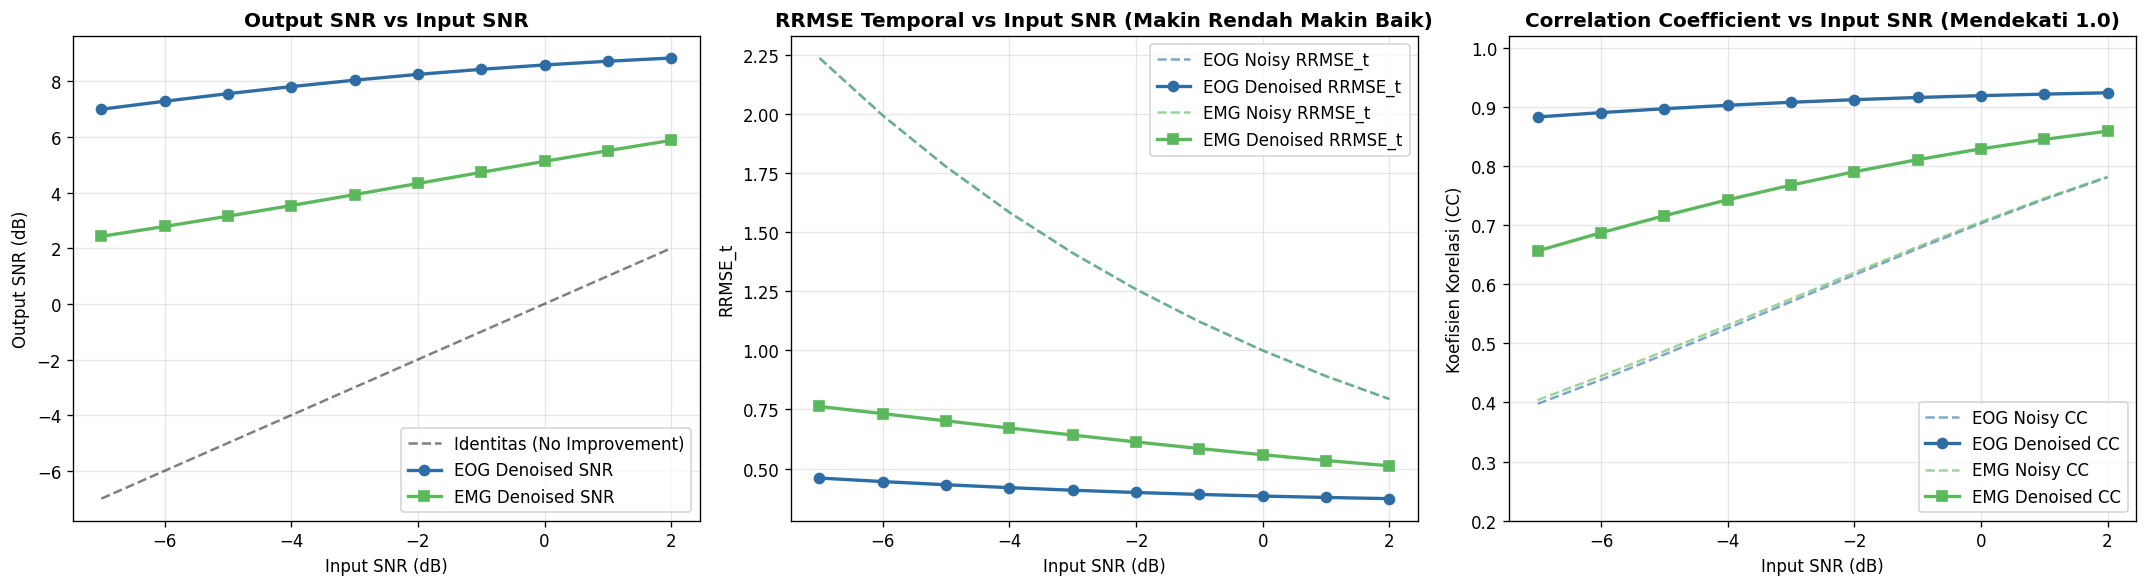

In [10]:
# Kurva Performa Lintas Tingkat SNR Input (-7 dB s/d +2 dB)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

snrs = sorted([int(k) for k in results["EOG"]["test_evaluation"]["by_snr"].keys()])

eog_res = results["EOG"]["test_evaluation"]["by_snr"]
emg_res = results["EMG"]["test_evaluation"]["by_snr"]

# 1. Output SNR vs Input SNR
axes[0].plot(snrs, snrs, "k--", alpha=0.5, label="Identitas (No Improvement)")
axes[0].plot(snrs, [eog_res[str(s)]["snr_out_db"] for s in snrs], "o-", color="#2e6da4", lw=2, label="EOG Denoised SNR")
axes[0].plot(snrs, [emg_res[str(s)]["snr_out_db"] for s in snrs], "s-", color="#5cb85c", lw=2, label="EMG Denoised SNR")
axes[0].set_title("Output SNR vs Input SNR", fontweight="bold")
axes[0].set_xlabel("Input SNR (dB)")
axes[0].set_ylabel("Output SNR (dB)")
axes[0].legend()

# 2. RRMSE_t vs Input SNR
axes[1].plot(snrs, [eog_res[str(s)]["rrmse_t_noisy"] for s in snrs], "--", color="#2e6da4", alpha=0.6, label="EOG Noisy RRMSE_t")
axes[1].plot(snrs, [eog_res[str(s)]["rrmse_t_denoised"] for s in snrs], "o-", color="#2e6da4", lw=2, label="EOG Denoised RRMSE_t")
axes[1].plot(snrs, [emg_res[str(s)]["rrmse_t_noisy"] for s in snrs], "--", color="#5cb85c", alpha=0.6, label="EMG Noisy RRMSE_t")
axes[1].plot(snrs, [emg_res[str(s)]["rrmse_t_denoised"] for s in snrs], "s-", color="#5cb85c", lw=2, label="EMG Denoised RRMSE_t")
axes[1].set_title("RRMSE Temporal vs Input SNR (Makin Rendah Makin Baik)", fontweight="bold")
axes[1].set_xlabel("Input SNR (dB)")
axes[1].set_ylabel("RRMSE_t")
axes[1].legend()

# 3. Correlation Coefficient (CC) vs Input SNR
axes[2].plot(snrs, [eog_res[str(s)]["cc_noisy"] for s in snrs], "--", color="#2e6da4", alpha=0.6, label="EOG Noisy CC")
axes[2].plot(snrs, [eog_res[str(s)]["cc_denoised"] for s in snrs], "o-", color="#2e6da4", lw=2, label="EOG Denoised CC")
axes[2].plot(snrs, [emg_res[str(s)]["cc_noisy"] for s in snrs], "--", color="#5cb85c", alpha=0.6, label="EMG Noisy CC")
axes[2].plot(snrs, [emg_res[str(s)]["cc_denoised"] for s in snrs], "s-", color="#5cb85c", lw=2, label="EMG Denoised CC")
axes[2].set_title("Correlation Coefficient vs Input SNR (Mendekati 1.0)", fontweight="bold")
axes[2].set_xlabel("Input SNR (dB)")
axes[2].set_ylabel("Koefisien Korelasi (CC)")
axes[2].set_ylim(0.2, 1.02)
axes[2].legend()

plt.tight_layout()
plt.show()


In [ ]:
# Tabel Ringkasan Rata-rata Metrik Evaluasi Keseluruhan (Overall Test Set)
print("=" * 95)
print(f"{'Artifact':<10} | {'RMSE (Noisy -> Den)':<22} | {'RRMSE_t':<10} | {'CC (Noisy -> Den)':<20} | {'SNR Improvement':<18}")
print("=" * 95)

for art in ["EOG", "EMG"]:
    ov = results[art]["test_evaluation"]["overall"]
    rmse_str = f"{ov['rmse_noisy']:.4f} -> {ov['rmse_denoised']:.4f}"
    cc_str = f"{ov['cc_noisy']:.4f} -> {ov['cc_denoised']:.4f}"
    snr_str = f"+{ov['delta_snr_db']:.2f} dB ({ov['snr_out_db']:.2f} dB)"
    print(f"{art:<10} | {rmse_str:<22} | {ov['rrmse_t_denoised']:<10.4f} | {cc_str:<20} | {snr_str:<18}")

print("=" * 95)
print("\nProfil Rinci Latensi Komputasi & I/O Disk (Batch Size = 1):")
for art in ["EOG", "EMG"]:
    lat = results[art]["test_evaluation"]["latency_disk_bs1"]
    print(f"\n--- Profil Latensi [{art}] ---")
    print(f"  1. Pure NN Inference (GPU/CPU)   : {lat.get('pure_model_infer_ms', lat.get('infer_ms', 0)):.2f} ms")
    print(f"  2. Encode PNG File ke Disk       : {lat.get('encode_file_ms', lat.get('encode_ms', 0)):.2f} ms")
    print(f"  3. Read & Parse PNG Input        : {lat.get('read_parse_ms', 0):.2f} ms")
    print(f"  4. Pack & Write PNG Output       : {lat.get('pack_write_ms', 0):.2f} ms")
    print(f"  5. Decode PNG File dari Disk     : {lat.get('decode_file_ms', lat.get('decode_ms', 0)):.2f} ms")
    print(f"  >> Total Latensi End-to-End      : {lat['total_ms_per_sample']:.2f} ms/sampel")
    print(f"  >> Throughput End-to-End         : {lat['throughput_samples_per_sec']:.1f} sampel/detik")


Artifact   | RMSE (Noisy -> Den)    | RRMSE_t    | CC (Noisy -> Den)    | SNR Improvement   
EOG        | 1.4809 -> 0.4211       | 0.4084     | 0.5916 -> 0.9074     | +10.55 dB (8.05 dB)
EMG        | 1.4809 -> 0.6413       | 0.6311     | 0.5957 -> 0.7704     | +6.64 dB (4.14 dB)

Profil Rinci Latensi Komputasi & I/O Disk (Batch Size = 1):

--- Profil Latensi [EOG] ---
  1. Pure NN Inference (GPU/CPU)   : 5.02 ms
  2. Encode PNG File ke Disk       : 0.96 ms
  3. Read & Parse PNG Input        : 4.49 ms
  4. Pack & Write PNG Output       : 1.14 ms
  5. Decode PNG File dari Disk     : 6.21 ms
  >> Total Latensi End-to-End      : 17.83 ms/sampel
  >> Throughput End-to-End         : 56.1 sampel/detik

--- Profil Latensi [EMG] ---
  1. Pure NN Inference (GPU/CPU)   : 4.74 ms
  2. Encode PNG File ke Disk       : 0.96 ms
  3. Read & Parse PNG Input        : 4.69 ms
  4. Pack & Write PNG Output       : 1.17 ms
  5. Decode PNG File dari Disk     : 6.33 ms
  >> Total Latensi End-to-End      : 17.9